# LLM Fine Tuning · Lesson 10 · Continued pretraining

Lessons 4 to 9 taught a model a **task**: a question in, one SQL query out. Continued pretraining teaches it a
**language**: the words, spellings and facts of a text the model reads badly, from raw text with no questions and no answers. This lab
leaves the SQL task, because that needs no raw text, and teaches the model Swahili Wikipedia instead. The domain was chosen by
measurement: on six candidate corpora, base Qwen2.5-0.5B was worst, per character, on Swahili and Yoruba (the lesson page shows the table).

The model is `Qwen2.5-0.5B`, the **base** model, not the instruct one (continued pretraining is done on base models, and the
smaller model lets us compare LoRA with full fine-tuning on one T4). Seven questions, each answered by a measurement:

1. **Does the model read Swahili badly?** Tokens per word and per long word, and held-out perplexity,
   on Swahili Wikipedia and on English Wikipedia text as a control.
2. **What would each way of training cost?** Parameters, optimizer memory and the embedding matrix, by arithmetic.
3. **What does LoRA learn?** Plain next-token training on all tokens, a rank-64 adapter.
4. **What does full fine-tuning learn?** Same data, same steps, every weight trained.
5. **What does replaying English change?** Full fine-tuning again with a quarter of the batches from English Wikipedia.
6. **Did it learn Swahili, and what did it forget?** Perplexity on both kinds of text and a fill-in-the-word test
   that a program scores, before and after.
7. **What is the trade?** All four systems side by side.

**Run it:** Runtime → Change runtime type → T4 GPU, then Runtime → Run all. About 50 minutes on a T4 (an estimate, see
section 4): downloads and tokenising about 5 minutes, four evaluations about 8, three training runs about 35.
The lesson that explains every result is at [docs.recohut.com](https://docs.recohut.com/courses/llm-fine-tuning/3-beyond-sft/10-continued-pretraining).

## 0. Install, load and prepare the data

In [1]:
# Pinned versions, so the code matches the lesson it was written for.
%pip install -q transformers==4.51.3 peft==0.15.2 accelerate==1.6.0 datasets==3.6.0

pip may report conflicts with packages Colab preinstalls. This lab does not use them. TRL is not needed: continued
pretraining is plain causal-language-model training, which the `transformers` `Trainer` does on its own.

In [2]:
import gc
import json
import math
import os
import random
import re
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import peft
import torch
import torch.nn.functional as F
import transformers
from datasets import Dataset
from huggingface_hub import hf_hub_download
from peft import LoraConfig, get_peft_model
from transformers import (AutoModelForCausalLM, AutoTokenizer, Trainer, TrainingArguments,
                          default_data_collator, set_seed)

%config InlineBackend.figure_formats = ['svg']
assert torch.cuda.is_available(), "Choose Runtime -> Change runtime type -> T4 GPU."

SEED = 42
set_seed(SEED)
MODEL_ID = "Qwen/Qwen2.5-0.5B"      # the base model (Apache 2.0)
DEVICE = "cuda"
AMP = True                          # fp16 mixed precision: weights stay in float32, a T4 has no bfloat16
BLOCK = 512                         # tokens per training block
N_TRAIN_BLOCKS = 3000               # 3000 x 512 = about 1.5M tokens per run, chosen in section 4
MICRO_BATCH = 4                     # blocks per forward pass; 4 x 4 accumulation = 16 blocks per optimizer step
ACCUM = 4
REPLAY_FRAC = 0.25                  # share of general-text blocks in the replay run
N_EVAL_BLOCKS = 100                 # held-out blocks per perplexity number
N_CLOZE = 500                       # fill-in-the-word items per text kind
N_TRAIN_DOCS = 4000                 # Swahili articles read for training (more than enough for N_TRAIN_BLOCKS)
LORA_R = 64
LR_LORA, LR_FULL = 2e-4, 2e-5       # one value each, not tuned (the lesson says why this matters)
GB = 1e9
t_notebook = time.perf_counter()
print("transformers", transformers.__version__, "| peft", peft.__version__)
print("GPU:", torch.cuda.get_device_name(0))

transformers 4.51.3 | peft 0.15.2
GPU: Tesla T4


**Two public corpora, both pinned to a commit.**

- **Domain text:** `wikimedia/wikipedia`, configuration `20231101.sw`: the Swahili Wikipedia dump of 1 November 2023, one 36 MB file.
  Licence CC BY-SA 3.0 and GFDL; credit the Wikipedia authors, and note that the share-alike condition applies to anything you
  publish that is derived from the text (a model trained on it is a legal question, not answered here). Articles under 800 characters
  (stubs) are dropped.
- **General text, for the control and for replay:** `Salesforce/wikitext`, `wikitext-103-raw-v1`
  (English Wikipedia, CC BY-SA 3.0). Its spaced punctuation (` @-@ `, ` , `) is repaired first, otherwise the model would be
  scored partly on formatting.

Training and held-out Swahili articles are different articles, and the notebook asserts that no article is in both.

In [3]:
SW_REV = "b04c8d1ceb2f5cd4588862100d08de323dccfbaa"
WIKI_REV = "b08601e04326c79dfdd32d625aee71d232d685c3"
sw_path = hf_hub_download("wikimedia/wikipedia", "20231101.sw/train-00000-of-00001.parquet", repo_type="dataset", revision=SW_REV)
wiki_test = hf_hub_download("Salesforce/wikitext", "wikitext-103-raw-v1/test-00000-of-00001.parquet", repo_type="dataset", revision=WIKI_REV)
wiki_train = hf_hub_download("Salesforce/wikitext", "wikitext-103-raw-v1/train-00000-of-00002.parquet", repo_type="dataset", revision=WIKI_REV)

sw = pd.read_parquet(sw_path)
sw = sw[sw["text"].str.len() >= 800].sample(frac=1.0, random_state=SEED).reset_index(drop=True)   # shuffled with a fixed seed
print(f"Swahili Wikipedia: {len(sw):,} articles of at least 800 characters")


def sw_docs(frame, want):
    """The first 4,000 characters of each article, so that many different articles are read."""
    return [t.strip()[:4000] for t in frame["text"][:want]], list(frame["id"][:want])


# Held-out articles first, training articles after them: different articles by construction.
heldout_docs, heldout_ids = sw_docs(sw, 300)
train_docs, train_ids = sw_docs(sw.iloc[300:], N_TRAIN_DOCS)
assert len(heldout_docs) == 300 and len(train_docs) == N_TRAIN_DOCS
assert not set(train_ids) & set(heldout_ids), "an article is in both the training and the held-out set"


def detok(t):
    """Undo WikiText's tokenised punctuation so the text reads as normal prose."""
    t = t.replace(" @-@ ", "-").replace(" @,@ ", ",").replace(" @.@ ", ".")
    t = re.sub(r" ([,.;:!?)%])", r"\1", t)
    t = re.sub(r"([(]) ", r"\1", t)
    return t.replace(" 's", "'s").replace(" n't", "n't").strip()


def wiki_docs(path, want, seed):
    """Paragraphs of at least 60 words (headings start with ' = '), shuffled with a fixed seed."""
    lines = [l for l in pd.read_parquet(path)["text"] if len(l.split()) >= 60 and not l.lstrip().startswith("=")]
    random.Random(seed).shuffle(lines)
    return [detok(l) for l in lines[:want]]


general_test = wiki_docs(wiki_test, 400, SEED)
general_train = wiki_docs(wiki_train, 6000, SEED)
print(f"held-out: {len(heldout_docs)} Swahili articles, {len(general_test)} English paragraphs; "
      f"training pool: {len(train_docs)} Swahili articles, {len(general_train)} English paragraphs")
print("\nSwahili sample:", heldout_docs[0][:260].replace("\n", " "))
print("English sample:", general_test[0][:260])

Swahili Wikipedia: 17,824 articles of at least 800 characters


held-out: 300 Swahili articles, 400 English paragraphs; training pool: 4000 Swahili articles, 6000 English paragraphs

Swahili sample: Kambi ya Wachawi ya Gambaga ni jamii iliyotengwa ndani ya kitongoji cha Gambaga katika Mkoa wa Kaskazini wa Ghana iliyoanzishwa katika karne ya 18 ili kushughulikia madai ya wachawi na wachawi ambao wamefukuzwa kutoka kwenye jamii zao.  Kambi hiyo ina takriban
English sample: Although Gore was well received by the British establishment, the work suffered from what Gore called a " tediousness of process ", and he considered requesting a transfer in 1798. In 1800 it ground to a halt because another board established by the treaty to 


In [4]:
tok = AutoTokenizer.from_pretrained(MODEL_ID)
EOS = tok.eos_token_id


def to_blocks(texts, n_blocks=None):
    """Concatenate documents (an end-of-text token between them) and cut into BLOCK-token blocks."""
    ids = []
    for enc in tok(texts)["input_ids"]:
        ids += enc + [EOS]
    blocks = [ids[i:i + BLOCK] for i in range(0, len(ids) - BLOCK + 1, BLOCK)]
    return blocks[:n_blocks] if n_blocks else blocks


train_domain = to_blocks(train_docs)
train_general = to_blocks(general_train)
need_general = int(N_TRAIN_BLOCKS * REPLAY_FRAC)
assert len(train_domain) >= N_TRAIN_BLOCKS, f"only {len(train_domain)} domain blocks; read more articles"
assert len(train_general) >= need_general
train_domain, train_general = train_domain[:N_TRAIN_BLOCKS], train_general[:need_general]
eval_domain = to_blocks(heldout_docs, N_EVAL_BLOCKS)
eval_general = to_blocks(general_test, N_EVAL_BLOCKS)
assert len(eval_domain) == N_EVAL_BLOCKS and len(eval_general) == N_EVAL_BLOCKS
assert all(len(b) == BLOCK for b in train_domain + train_general + eval_domain + eval_general)
print(f"Swahili training blocks {len(train_domain):,} ({len(train_domain) * BLOCK / 1e6:.2f}M tokens), "
      f"general replay blocks {len(train_general):,}")
print(f"held-out blocks: {len(eval_domain)} Swahili, {len(eval_general)} English ({len(eval_domain) * BLOCK:,} tokens each)")

Swahili training blocks 3,000 (1.54M tokens), general replay blocks 750
held-out blocks: 100 Swahili, 100 English (51,200 tokens each)


## 1. Does the model read Swahili badly?

A tokenizer cuts text into pieces from a fixed vocabulary. A word that is common in the training text is one piece; a rare
technical word is cut into several. More pieces per word costs context length and compute, and usually means the
model saw that word seldom. Three measurements, all with the model's own tokenizer:

- **tokens per word** over whole held-out documents, Swahili against English;
- **tokens per long word:** the average for words of nine or more letters;
- **how some words are cut**, as a picture of what the model actually reads.

Held-out perplexity, which is the more direct measure, comes in section 2.

In [5]:
def tokens_per_word(texts):
    words = sum(len(t.split()) for t in texts)
    pieces = sum(len(e) for e in tok(texts)["input_ids"])
    return pieces / words


LONG = re.compile(r"\b[a-z]{9,}\b")


def long_terms(texts):
    return [w for t in texts for w in LONG.findall(t)]


def pieces(word):
    return len(tok(" " + word)["input_ids"])


dom_terms, gen_terms = long_terms(heldout_docs), long_terms(general_test)
vocab = {
    "Swahili": {"tokens per word": tokens_per_word(heldout_docs),
               "tokens per long word": np.mean([pieces(w) for w in dom_terms]),
               "long words cut in 3+ pieces, %": 100 * np.mean([pieces(w) >= 3 for w in dom_terms])},
    "English": {"tokens per word": tokens_per_word(general_test),
                "tokens per long word": np.mean([pieces(w) for w in gen_terms]),
                "long words cut in 3+ pieces, %": 100 * np.mean([pieces(w) >= 3 for w in gen_terms])},
}
print(pd.DataFrame(vocab).round(2).to_string())
print(f"\n({len(dom_terms):,} Swahili and {len(gen_terms):,} English long-word occurrences)")

freq = pd.Series(dom_terms).value_counts()
rare = [w for w in freq.index if pieces(w) >= 4][:6]
for w in rare:
    print(f"{w:22s} -> {[tok.decode(i) for i in tok(' ' + w)['input_ids']]}")

                                Swahili  English
tokens per word                    2.50     1.37
tokens per long word               4.16     1.32
long words cut in 3+ pieces, %    95.53     7.98

(6,977 Swahili and 3,874 English long-word occurrences)
mbalimbali             -> [' mb', 'al', 'imb', 'ali']
alizaliwa              -> [' al', 'iz', 'ali', 'wa']
kaskazini              -> [' k', 'ask', 'az', 'ini']
mwigizaji              -> [' m', 'wig', 'iz', 'aji']
wanafunzi              -> [' wan', 'af', 'un', 'zi']
mtakatifu              -> [' mt', 'ak', 'at', 'ifu']


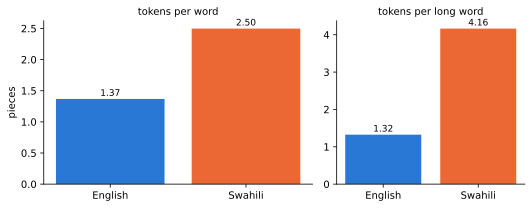

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(7.5, 3), gridspec_kw={"width_ratios": [2, 1.4]})
for a, key in zip(ax, ["tokens per word", "tokens per long word"]):
    vals = [vocab["English"][key], vocab["Swahili"][key]]
    a.bar(["English", "Swahili"], vals, color=["#2a78d6", "#eb6834"])
    for i, v in enumerate(vals):
        a.text(i, v + 0.02 * max(vals), f"{v:.2f}", ha="center", fontsize=9)
    a.set_title(key, fontsize=10)
    a.spines[["top", "right"]].set_visible(False)
ax[0].set_ylabel("pieces")
plt.tight_layout()
plt.show()

## 2. Measuring before training: perplexity and a fill-in-the-word test

**Perplexity** is the exponential of the average negative log-probability the model gives each next token of text it
has not seen: $\mathrm{PPL}=\exp\left(-\frac{1}{N}\sum_{t}\log p(x_t\mid x_{<t})\right)$. Lower means less surprised. It is
computed here on 100 held-out blocks of 512 tokens, once for Swahili text and once for English text. In the code and tables, "domain" means Swahili and "general" means English. The English number is the
**forgetting meter**: it should not rise much. (The model has certainly read Wikipedia; that is the point of using it to
see what is lost.) Perplexity is only comparable across models that share a tokenizer, which is true here.

**A test a program can score.** Perplexity says the text got less surprising, not that the model knows more. The second
measure is a fill-in test built from held-out sentences: pick a long word that the tokenizer cuts into three or more pieces, make
four versions of the sentence (the real word and three other long words of similar length from the same article, so they fit the topic), and let the model
choose the version it finds most likely. Chance is 25%. The same test is built
from English sentences as the general check. It measures whether the model prefers the right long word in context; it
is not a Swahili exam, and a sentence with fewer pieces tends to score higher, which is why the distractors are matched on
length. It is a relative score for comparing systems.

In [7]:
WORD8 = re.compile(r"\b[a-z]{8,}\b")
_pieces_cache = {}


def n_pieces(w):
    if w not in _pieces_cache:
        _pieces_cache[w] = pieces(w)
    return _pieces_cache[w]


def make_cloze(docs, n, seed):
    """Items of four sentence versions; version 0 holds the real word. Distractors come from the same document."""
    rng = random.Random(seed)
    sents = [(i, s) for i, t in enumerate(docs) for s in re.split(r"(?<=[.!?])\s+", t.replace("\n", " ")) if 80 <= len(s) <= 300]
    terms = [sorted({w for w in WORD8.findall(t) if n_pieces(w) >= 3}) for t in docs]
    rng.shuffle(sents)
    items = []
    for i, s in sents:
        hits = [m for m in WORD8.finditer(s) if m.start() > 0 and n_pieces(m.group()) >= 3]
        if not hits:
            continue
        m = rng.choice(hits)
        target = m.group()
        others = [w for w in terms[i] if w != target and abs(len(w) - len(target)) <= 2 and w not in s.lower()]
        if len(others) < 3:
            continue
        options = [target] + rng.sample(others, 3)
        items.append({"options": options, "texts": [s[:m.start()] + o + s[m.end():] for o in options]})
        if len(items) == n:
            break
    assert len(items) == n, f"only {len(items)} items"
    return items


# English words rarely split into three or more pieces, so the English items come from every qualifying paragraph of the
# WikiText test split (1,547; none is used for training or replay). Paragraphs are grouped in eights so that "the same
# document" has enough long words to offer three distractors.
cloze_pool = wiki_docs(wiki_test, 100_000, SEED)
general_groups = ["\n".join(cloze_pool[i:i + 8]) for i in range(0, len(cloze_pool), 8)]
cloze = {"domain": make_cloze(heldout_docs, N_CLOZE, SEED), "general": make_cloze(general_groups, N_CLOZE, SEED)}
for kind, items in cloze.items():
    assert all(len(set(i["options"])) == 4 and len(set(i["texts"])) == 4 for i in items)
    print(f"{kind}: {len(items)} items, example options {items[0]['options']}")
    print("   ", items[0]["texts"][0][:200])

domain: 500 items, example options ['magharibi', 'maendeleo', 'gerezani', 'alisimamia']
    Honecker alikazia utawala wa kisiasa katika himaya yake, alikandamiza upinzani wowote na kuimarisha mpaka ndani ya Ujeruamni ambako mamia waliuawa walipojaribu kutoroka kutoka mashariki kwenda maghari
general: 500 items, example options ['temnospondyls', 'camouflaged', 'trematosauroids', 'brachyopids']
    The Triassic-Jurassic extinction event around 199.6 Mya led to the extinction of most Mesozoic temnospondyls.


In [8]:
def autocast():
    return torch.autocast("cuda" if DEVICE == "cuda" else "cpu", dtype=torch.float16, enabled=AMP)


@torch.inference_mode()
def perplexity(model, blocks, batch=4):
    """Mean next-token loss (nats) over all predicted tokens, and its exponential."""
    nll, n = 0.0, 0
    for i in range(0, len(blocks), batch):
        x = torch.tensor(blocks[i:i + batch]).to(DEVICE)
        with autocast():
            logits = model(input_ids=x).logits
        nll += F.cross_entropy(logits[:, :-1].float().reshape(-1, logits.shape[-1]), x[:, 1:].reshape(-1), reduction="sum").item()
        n += x[:, 1:].numel()
    return nll / n, math.exp(nll / n)


@torch.inference_mode()
def sentence_logprobs(model, texts, batch=16):
    """Total log-probability of each text, given a start-of-text token."""
    out = []
    for i in range(0, len(texts), batch):
        enc = [[EOS] + tok(t)["input_ids"] for t in texts[i:i + batch]]
        width = max(map(len, enc))
        ids = torch.full((len(enc), width), EOS)
        mask = torch.zeros(len(enc), width)
        for j, e in enumerate(enc):
            ids[j, :len(e)] = torch.tensor(e)
            mask[j, :len(e)] = 1
        ids, mask = ids.to(DEVICE), mask.to(DEVICE)
        with autocast():
            logits = model(input_ids=ids, attention_mask=mask).logits
        lp = torch.log_softmax(logits[:, :-1].float(), -1).gather(2, ids[:, 1:, None])[..., 0]
        out += (lp * mask[:, 1:]).sum(1).tolist()
    return out


def cloze_accuracy(model, items):
    flat = [t for it in items for t in it["texts"]]
    lp = np.array(sentence_logprobs(model, flat)).reshape(len(items), 4)
    return float((lp.argmax(1) == 0).mean())


PROMPTS = [" ".join(d.split()[:35]) for d in heldout_docs[:3]]


@torch.inference_mode()
def continuations(model, new_tokens=40):
    outs = []
    for p in PROMPTS:
        enc = tok(p, return_tensors="pt").to(DEVICE)
        with autocast():
            g = model.generate(**enc, max_new_tokens=new_tokens, do_sample=False, pad_token_id=EOS)
        outs.append(tok.decode(g[0, enc["input_ids"].shape[1]:], skip_special_tokens=True))
    return outs


def evaluate_all(model, name):
    """Domain and general perplexity, both fill-in tests, and three greedy continuations."""
    model.eval()
    t0 = time.perf_counter()
    d_loss, d_ppl = perplexity(model, eval_domain)
    g_loss, g_ppl = perplexity(model, eval_general)
    r = {"domain loss": d_loss, "domain ppl": d_ppl, "general loss": g_loss, "general ppl": g_ppl,
         "domain fill-in": cloze_accuracy(model, cloze["domain"]), "general fill-in": cloze_accuracy(model, cloze["general"]),
         "samples": continuations(model)}
    print(f"{name:20s} domain ppl {d_ppl:7.2f}  general ppl {g_ppl:7.2f}  domain fill-in {r['domain fill-in']:.1%}  "
          f"general fill-in {r['general fill-in']:.1%}  ({time.perf_counter() - t0:.0f} s)")
    return r


def load_model():
    """Weights in float32: fp16 mixed precision needs float32 master weights for full fine-tuning."""
    m = AutoModelForCausalLM.from_pretrained(MODEL_ID, torch_dtype=torch.float32).to(DEVICE)
    m.config.use_cache = False
    return m


def free_gpu():
    gc.collect()
    if DEVICE == "cuda":
        torch.cuda.empty_cache()


results, runs_info = {}, {}
base = load_model()
base.config.use_cache = True
results["base model"] = evaluate_all(base, "base model")

base model           domain ppl   80.60  general ppl   20.07  domain fill-in 29.0%  general fill-in 88.6%  (38 s)


## 3. What would each way of training cost?

Plain continued pretraining is the same objective as the original pretraining: predict every next token, with the loss on
**all** tokens (there is no prompt to mask). Two ways to spend the update:

- **Full fine-tuning** trains every weight. With the AdamW optimizer each trained weight needs its float32 value, a gradient and two moments:
  16 bytes.
- **LoRA** (lesson 2) trains two small matrices beside each linear layer. Its adapter is rank 64 with `alpha` 128 on every linear
  layer: the rank is higher than lesson 4's, and `alpha` is twice the rank, because the learning-vs-forgetting study of LoRA
  in the lesson found low ranks too small for continued pretraining and `alpha = 2r` necessary.

A third option is to also train the **embedding matrix**, because new vocabulary lives there. The cell below prices it. This model ties
its input embeddings and its output layer, so they are one matrix.

In [9]:
n_all = sum(p.numel() for p in base.parameters())
emb = base.get_input_embeddings().weight
n_emb = emb.numel()
probe = get_peft_model(load_model(), LoraConfig(r=LORA_R, lora_alpha=2 * LORA_R, lora_dropout=0.0, target_modules="all-linear",
                                                 task_type="CAUSAL_LM"))
n_lora = sum(p.numel() for p in probe.parameters() if p.requires_grad)
print(f"base model: {n_all:,} parameters, of which the embedding matrix {tuple(emb.shape)} is {n_emb:,} ({n_emb / n_all:.1%})")
print(f"tied input and output embeddings: {base.config.tie_word_embeddings}")
print(f"LoRA r={LORA_R}, alpha={2 * LORA_R}, all linear layers: {n_lora:,} trainable ({n_lora / n_all:.1%} of the base)")
print("\nEstimated training state in GB (weights + gradients + AdamW moments, float32; activations not included):")
est = pd.Series({
    "full fine-tuning (16 bytes per weight)": 16 * n_all / GB,
    "LoRA (4 bytes per base weight + 16 per adapter weight)": (4 * n_all + 16 * n_lora) / GB,
    "LoRA + trained embedding matrix (extra 16 bytes per embedding weight)": (4 * n_all + 16 * (n_lora + n_emb)) / GB,
})
print(est.round(2).to_string())
del probe
free_gpu()

base model: 494,032,768 parameters, of which the embedding matrix (151936, 896) is 136,134,656 (27.6%)
tied input and output embeddings: True
LoRA r=64, alpha=128, all linear layers: 35,192,832 trainable (7.1% of the base)

Estimated training state in GB (weights + gradients + AdamW moments, float32; activations not included):
full fine-tuning (16 bytes per weight)                                   7.90
LoRA (4 bytes per base weight + 16 per adapter weight)                   2.54
LoRA + trained embedding matrix (extra 16 bytes per embedding weight)    4.72


## 4. How big a run?

The memory is set by the micro-batch (4 blocks of 512 tokens, 4 steps of accumulation, so 16 blocks or 8,192 tokens per optimizer
step) and by gradient checkpointing. The time is set by the tokens. One pass over 3,000 blocks is about 1.5 million tokens and
about 190 optimizer steps. On a T4 a 0.5B model trains at roughly 2,500 to 5,000 tokens per second in fp16 mixed precision with checkpointing
(an estimate from 6 FLOPs per parameter per token, plus a third more for recomputation, at 15 to 25% of the T4's fp16 peak),
so one run takes roughly 5 to 10 minutes; the notebook prints the measured speed, so `N_TRAIN_BLOCKS` is one constant to rescale.
This is a small continued pretraining run, far below the company runs in the lesson. It shows the mechanism
and the measurements, not what a production run reaches.

All three runs use the same blocks, the same number of optimizer steps and the same seed. The replay run swaps a quarter of the
Swahili blocks for English blocks, so it sees fewer Swahili tokens in the same compute.

In [10]:
def train(model, blocks, name, lr):
    """Plain causal-LM training: labels are the inputs, the loss is on every token."""
    ds = Dataset.from_dict({"input_ids": blocks, "labels": blocks})
    args = TrainingArguments(
        output_dir=f"out-{name}", per_device_train_batch_size=MICRO_BATCH, gradient_accumulation_steps=ACCUM,
        num_train_epochs=1, learning_rate=lr, lr_scheduler_type="cosine", warmup_ratio=0.03, weight_decay=0.0,
        max_grad_norm=1.0, fp16=AMP, use_cpu=(DEVICE == "cpu"),
        gradient_checkpointing=True, gradient_checkpointing_kwargs={"use_reentrant": False},
        logging_steps=10, save_strategy="no", report_to="none", seed=SEED)
    trainer = Trainer(model=model, args=args, train_dataset=ds, data_collator=default_data_collator)
    free_gpu()
    if DEVICE == "cuda":
        torch.cuda.reset_peak_memory_stats()
    start = time.perf_counter()
    trainer.train()
    secs = time.perf_counter() - start
    info = {"minutes": secs / 60, "tokens/s": len(blocks) * BLOCK / secs, "peak GB": torch.cuda.max_memory_allocated() / GB,
            "steps": trainer.state.global_step, "log": pd.DataFrame(trainer.state.log_history).dropna(subset=["loss"])[["step", "loss"]]}
    print(f"\n{name}: {info['minutes']:.1f} min, {info['tokens/s']:,.0f} tokens/s, peak {info['peak GB']:.2f} GB, {info['steps']} steps")
    return trainer, info


def finish(trainer, name):
    trainer.model.config.use_cache = True
    results[name] = evaluate_all(trainer.model, name)

## 5. What does LoRA learn?

Rank 64, `alpha` 128, no dropout, every linear layer, learning rate $2\times10^{-4}$. LoRA uses a learning rate about ten times
larger than full fine-tuning. These values were picked once, not swept; with a sweep each method would get its own best rate
(the lesson explains why that matters for any comparison between the two).

In [11]:
del base
free_gpu()
lora_model = get_peft_model(load_model(), LoraConfig(r=LORA_R, lora_alpha=2 * LORA_R, lora_dropout=0.0,
                                                      target_modules="all-linear", task_type="CAUSAL_LM"))
trainer, runs_info["LoRA r=64"] = train(lora_model, train_domain, "lora", LR_LORA)
lora_model.save_pretrained("lora-adapter")
runs_info["LoRA r=64"]["adapter MB"] = sum(os.path.getsize(os.path.join("lora-adapter", f)) for f in os.listdir("lora-adapter")) / 1e6
finish(trainer, "LoRA r=64")
del trainer, lora_model
free_gpu()

Step,Training Loss
10,4.117100
20,3.644000
30,3.416300
40,3.283800
50,3.140700
60,3.036800
70,3.003200
80,2.923100
90,2.911400
100,2.824900



lora: 9.5 min, 2,681 tokens/s, peak 7.33 GB, 187 steps


LoRA r=64            domain ppl   15.43  general ppl   22.76  domain fill-in 58.4%  general fill-in 88.6%  (57 s)


## 6. What does full fine-tuning learn?

The same blocks and steps, every weight trained, learning rate $2\times10^{-5}$. The weights, gradients and optimizer
moments are all float32, so this is the run that is closest to the memory limit of the T4.

In [12]:
full_model = load_model()
trainer, runs_info["full fine-tune"] = train(full_model, train_domain, "full", LR_FULL)
runs_info["full fine-tune"]["adapter MB"] = None
finish(trainer, "full fine-tune")
del trainer, full_model
free_gpu()

Step,Training Loss
10,4.085900
20,3.540600
30,3.301300
40,3.164900
50,3.022800
60,2.917900
70,2.889500
80,2.812100
90,2.791200
100,2.707000



full: 9.2 min, 2,769 tokens/s, peak 12.80 GB, 187 steps


full fine-tune       domain ppl   13.84  general ppl   22.37  domain fill-in 56.8%  general fill-in 88.8%  (43 s)


## 7. What does replaying English change?

Forgetting is the cost of changing the weights toward one distribution. **Replay** keeps showing the model some of the old
distribution while it learns the new one. Here a quarter of the 3,000 blocks are English Wikipedia paragraphs and the rest are Swahili
text, shuffled together by the trainer. Everything else matches section 6. One caveat is built in: the replay text and the
general control text are both English Wikipedia, so the control cannot say how well replay protects against kinds of English that were
not replayed (code, other registers) or other languages. The lesson returns to this.

In [13]:
n_domain = N_TRAIN_BLOCKS - len(train_general)
mix = train_domain[:n_domain] + train_general
assert len(mix) == N_TRAIN_BLOCKS
print(f"{n_domain:,} domain blocks + {len(train_general):,} general blocks = {len(mix):,}")
full_model = load_model()
trainer, runs_info["full + replay"] = train(full_model, mix, "replay", LR_FULL)
runs_info["full + replay"]["adapter MB"] = None
finish(trainer, "full + replay")
del trainer, full_model
free_gpu()

2,250 domain blocks + 750 general blocks = 3,000


Step,Training Loss
10,3.943800
20,3.431900
30,3.249800
40,3.179200
50,3.050400
60,3.007200
70,3.000100
80,2.895900
90,2.917900
100,2.869400



replay: 9.2 min, 2,769 tokens/s, peak 12.80 GB, 187 steps


full + replay        domain ppl   15.45  general ppl   18.22  domain fill-in 53.4%  general fill-in 89.8%  (43 s)


## 8. Did it learn Swahili, and what did it forget?

The ± columns are 95% intervals on the fill-in accuracy, $1.96\sqrt{p(1-p)/n}$ with $n$ = the number of items; perplexity
has no interval here because it is one pass over one fixed set of held-out blocks. **Change** columns compare each system with the
base model.

In [14]:
order = ["base model", "LoRA r=64", "full fine-tune", "full + replay"]
tab = pd.DataFrame({k: {m: v for m, v in results[k].items() if m != "samples"} for k in order}).T
tab["domain fill-in ±"] = 1.96 * np.sqrt(tab["domain fill-in"] * (1 - tab["domain fill-in"]) / N_CLOZE)
tab["general fill-in ±"] = 1.96 * np.sqrt(tab["general fill-in"] * (1 - tab["general fill-in"]) / N_CLOZE)
show = pd.DataFrame({
    "domain ppl": tab["domain ppl"].round(2), "general ppl": tab["general ppl"].round(2),
    "domain loss change": (tab["domain loss"] - tab.loc["base model", "domain loss"]).round(3),
    "general loss change": (tab["general loss"] - tab.loc["base model", "general loss"]).round(3),
    "domain fill-in, %": (100 * tab["domain fill-in"]).round(1), "±": (100 * tab["domain fill-in ±"]).round(1),
    "general fill-in, %": (100 * tab["general fill-in"]).round(1), "± ": (100 * tab["general fill-in ±"]).round(1)})
print(show.to_string())
print("\n(loss change is in nats per token; negative = better than the base model)")

                domain ppl  general ppl  domain loss change  general loss change  domain fill-in, %    ±  general fill-in, %   ± 
base model           80.60        20.07               0.000                0.000               29.0  4.0                88.6  2.8
LoRA r=64            15.43        22.76              -1.653                0.126               58.4  4.3                88.6  2.8
full fine-tune       13.84        22.37              -1.762                0.109               56.8  4.3                88.8  2.8
full + replay        15.45        18.22              -1.652               -0.097               53.4  4.4                89.8  2.7

(loss change is in nats per token; negative = better than the base model)


In [15]:
cost = pd.DataFrame({k: {m: v for m, v in runs_info[k].items() if m != "log"} for k in runs_info}).T
cost["minutes"] = cost["minutes"].astype(float).round(1)
cost["tokens/s"] = cost["tokens/s"].astype(float).round(0)
cost["peak GB"] = cost["peak GB"].astype(float).round(2)
cost["trained parameters"] = pd.Series({"LoRA r=64": n_lora, "full fine-tune": n_all, "full + replay": n_all})
print(cost.to_string())
print("\nSaved on disk if kept in float16: full model about", round(n_all * 2 / 1e6), "MB; LoRA adapter (float32 matrices):",
      round(runs_info["LoRA r=64"]["adapter MB"], 1), "MB")

                minutes  tokens/s  peak GB  steps  adapter MB  trained parameters
LoRA r=64           9.5    2681.0     7.33  187.0  140.821893            35192832
full fine-tune      9.2    2769.0    12.80  187.0         NaN           494032768
full + replay       9.2    2769.0    12.80  187.0         NaN           494032768

Saved on disk if kept in float16: full model about 988 MB; LoRA adapter (float32 matrices): 140.8 MB


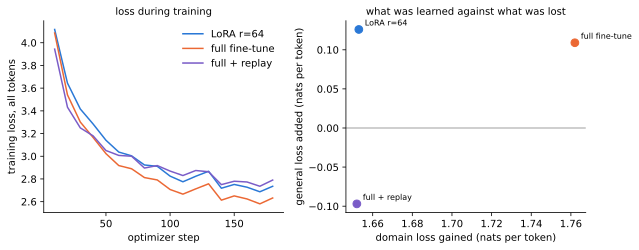

In [16]:
fig, ax = plt.subplots(1, 2, figsize=(9, 3.6))
colors = {"LoRA r=64": "#2a78d6", "full fine-tune": "#eb6834", "full + replay": "#7a5cc7"}
for name, info in runs_info.items():
    ax[0].plot(info["log"]["step"], info["log"]["loss"], color=colors[name], label=name)
ax[0].set_xlabel("optimizer step")
ax[0].set_ylabel("training loss, all tokens")
ax[0].legend(frameon=False)
ax[0].set_title("loss during training", fontsize=10)
for name in order[1:]:
    x = -(show.loc[name, "domain loss change"])
    y = show.loc[name, "general loss change"]
    ax[1].scatter(x, y, s=60, color=colors[name])
    ax[1].annotate(name, (x, y), textcoords="offset points", xytext=(6, 4), fontsize=8)
ax[1].axhline(0, color="#888", lw=0.8)
ax[1].set_xlabel("domain loss gained (nats per token)")
ax[1].set_ylabel("general loss added (nats per token)")
ax[1].set_title("what was learned against what was lost", fontsize=10)
for a in ax:
    a.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

### What the models write

The same three held-out Swahili article openings (first 35 words), continued greedily for 40 tokens. Continuations are an illustration, not a
score: a base model continues text, it does not answer, so look at vocabulary and whether it stays on topic.

In [17]:
for i, p in enumerate(PROMPTS):
    print(f"--- prompt {i}: {p[:160]}...")
    for name in order:
        print(f"[{name}] {results[name]['samples'][i].strip()[:230]!r}")
    print()

--- prompt 0: Kambi ya Wachawi ya Gambaga ni jamii iliyotengwa ndani ya kitongoji cha Gambaga katika Mkoa wa Kaskazini wa Ghana iliyoanzishwa katika karne ya 18 ili kushughul...
[base model] 'kwa 18 ili kushughulikia madai ya wachawi na wachawi ambao wamefukuzwa kutoka kwenye kwa 18'
[LoRA r=64] 'kikosi cha kwanza cha kijamii cha kwanza cha kijamii cha kwanza cha kijamii cha kwanza cha kijamii cha'
[full fine-tune] 'mkoa wa Kaskazini. \n\nKwa kawaida, kwa kawaida, kwa kawaida, kwa kawaida, kwa kawaida, k'
[full + replay] 'kusini kwa kusini kwa kusini. \n\nKwa kawaida, kwa kusini kwa kusini, kwa kusini kwa k'

--- prompt 1: Nyumba ya wageni (pia "gesti" kutoka Kiing. guest house) ni jengo penye nafasi za kukodi kwa kulala wageni. Ndani yake kuna sehemu ya mapokezi, vyumba vya kulal...
[base model] '"gesti" kutoka Kiing. Guest house is a guest house. It is a guest house. It is a guest house. It is a guest house. It is a guest house.'
[LoRA r=64] 'na kufanya kazi kwa kufanya kazi kwa kufa

## 9. What is the trade?

One summary line per system: what it cost, what it gained on Swahili, what it lost on English.

In [18]:
summary = pd.DataFrame({
    "minutes": cost["minutes"], "peak GB": cost["peak GB"],
    "domain loss gained": -show["domain loss change"], "general loss added": show["general loss change"],
    "domain fill-in, points": (show["domain fill-in, %"] - show.loc["base model", "domain fill-in, %"]).round(1),
    "general fill-in, points": (show["general fill-in, %"] - show.loc["base model", "general fill-in, %"]).round(1),
}).drop("base model")
print(summary.to_string())
print(f"\nwhole notebook: {(time.perf_counter() - t_notebook) / 60:.0f} minutes")

                minutes  peak GB  domain loss gained  general loss added  domain fill-in, points  general fill-in, points
LoRA r=64           9.5     7.33               1.653               0.126                    29.4                      0.0
full + replay       9.2    12.80               1.652              -0.097                    24.4                      1.2
full fine-tune      9.2    12.80               1.762               0.109                    27.8                      0.2

whole notebook: 32 minutes


## Read the result

- **Check how badly the model reads the language before you train,** and choose the language by measurement, not by assumption. Tokens per word, tokens per long word and held-out
  perplexity say whether there is anything to gain. If the base model already reads the text well, expect a small gain.
- **Perplexity going down is not knowledge going up.** The fill-in test is a second, program-scored measure; the interval on it
  says how much of a difference is noise.
- **Always measure the control.** The English rows are the cost of the gain. A gain with no control number is half a result.
- **LoRA and full fine-tuning are two points on a learning-and-forgetting curve,** not a winner and a loser: compare the table
  and the right-hand chart, not one column.
- **Replay is cheap and measurable,** but it only protects the kind of text you replay.
- **Everything here is small.** About 1.5 million tokens on a 0.5B model; the companies in the lesson trained on billions to
  a trillion tokens.

The lesson explains each result and the companies that learned the same lessons at scale:
[Continued pretraining](https://docs.recohut.com/courses/llm-fine-tuning/3-beyond-sft/10-continued-pretraining).